# 6. Discretisation and parameters

In this notebook, we study the two families of numbers that govern a solve. The
grid determines how much of the geometry the discretisation keeps and how much
memory the solve needs. The model parameters, the transition costs $k_1, k_2$
and the speed coefficients $\nu_{FWD}, \nu_{2WS}, \nu_{4WS}, \gamma_{rev}$, set
what the planner considers expensive.

The studies behind this notebook solve several hundred problems on the GPU.
`scripts/acquire_sensitivity.py` produced them and their results are in
`data/sensitivity/`. We run, on the CPU, the figure scripts of `generators/`
that read those results, and display their figures. The scripts also write
tables of values under `figures/tables/`, `parameter_study.md` and
`clearance_cap.md`; every number quoted in the text can be read there. The
labels drawn on the figures are in French, as in the thesis.

**Summary**

1. [Grid resolution](#1)
2. [How a coarse grid closes a passage](#2)
3. [Five situations on Two-Rooms](#3)
4. [One parameter at a time](#4)
5. [The transition costs, and the choice of (2, 3)](#5)
6. [The cap on the obstacle cost](#6)

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

from IPython.display import Image, display
from shfm import generators as GEN


def show(name):
    "Display one PNG written by a figure script."
    display(Image(GEN.figure_path(name)))

<a id='1'></a>
## 1. Grid resolution

The eikonal equation is solved on a grid over $(x, y, \theta, s)$. The angular
axis stays at $N_\theta = 100$ throughout, and only the spatial resolution
varies: three scenes, Two-Rooms, Narrow-Passage and Warehouse, each solved on
six grids from 50 to 200 cells a side over the same frame, so that a length
measured on one grid compares with the next.

The map of each grid is cut from the source map with a conservative
rasterisation: a cell is an obstacle as soon as it overlaps an obstacle of the
source. A coarse grid can then close a passage, never open one the vehicle
cannot use. Two-Rooms and Warehouse are solved at the centre of the parameter
study, $k_1 = 10$, $k_2 = 50$, with the clearance term uncapped; on
Narrow-Passage every change of mode costs one unit and the clearance is capped.

We draw the paths of the six grids over each map, coarse (dark) to fine
(light); a path that ends further than a vehicle length from its start or its
goal is dashed.

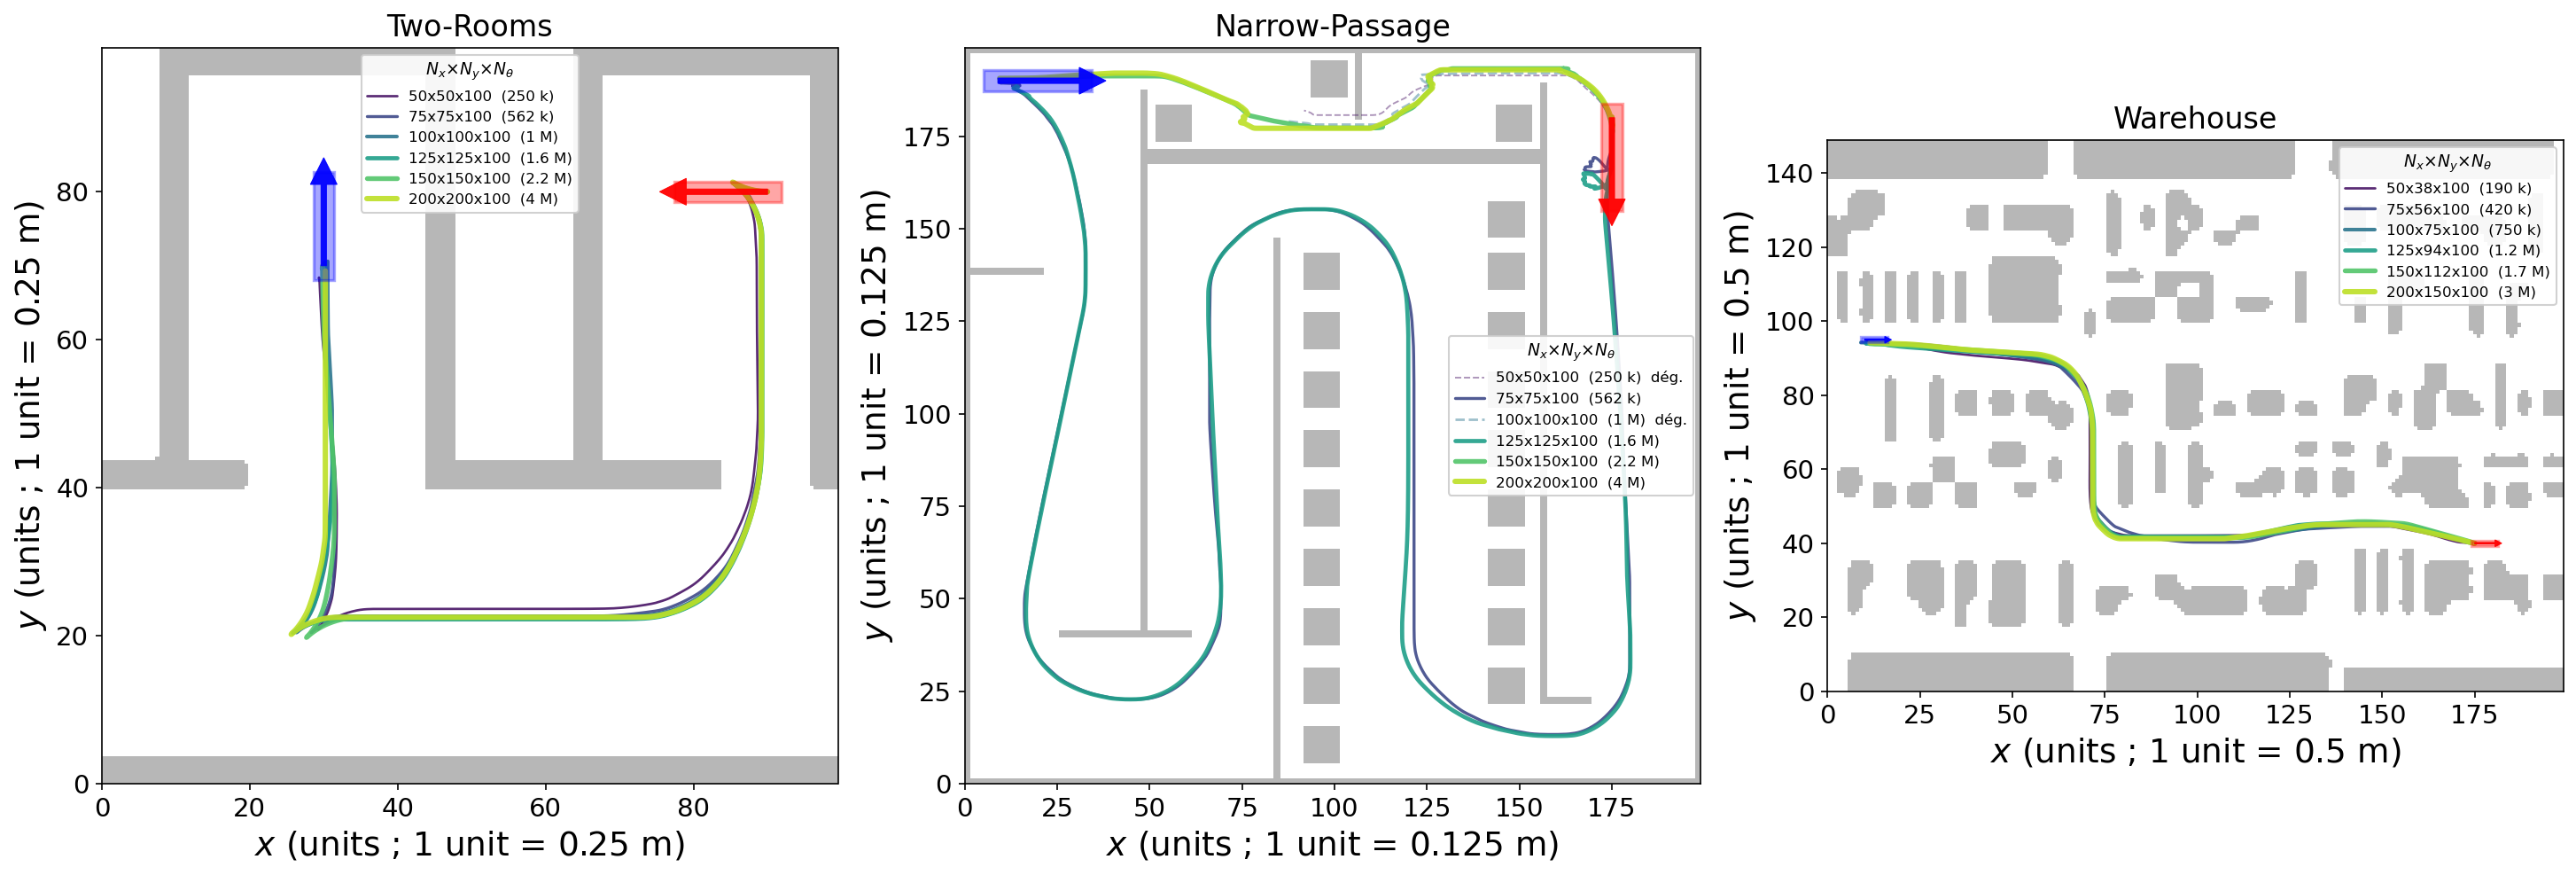

In [2]:
GEN.run("resolution")
show("resolution_traj_overlay.png")

Per scene, we plot the solve time and the peak GPU memory against the number
of grid points, and the length relative to the finest grid.

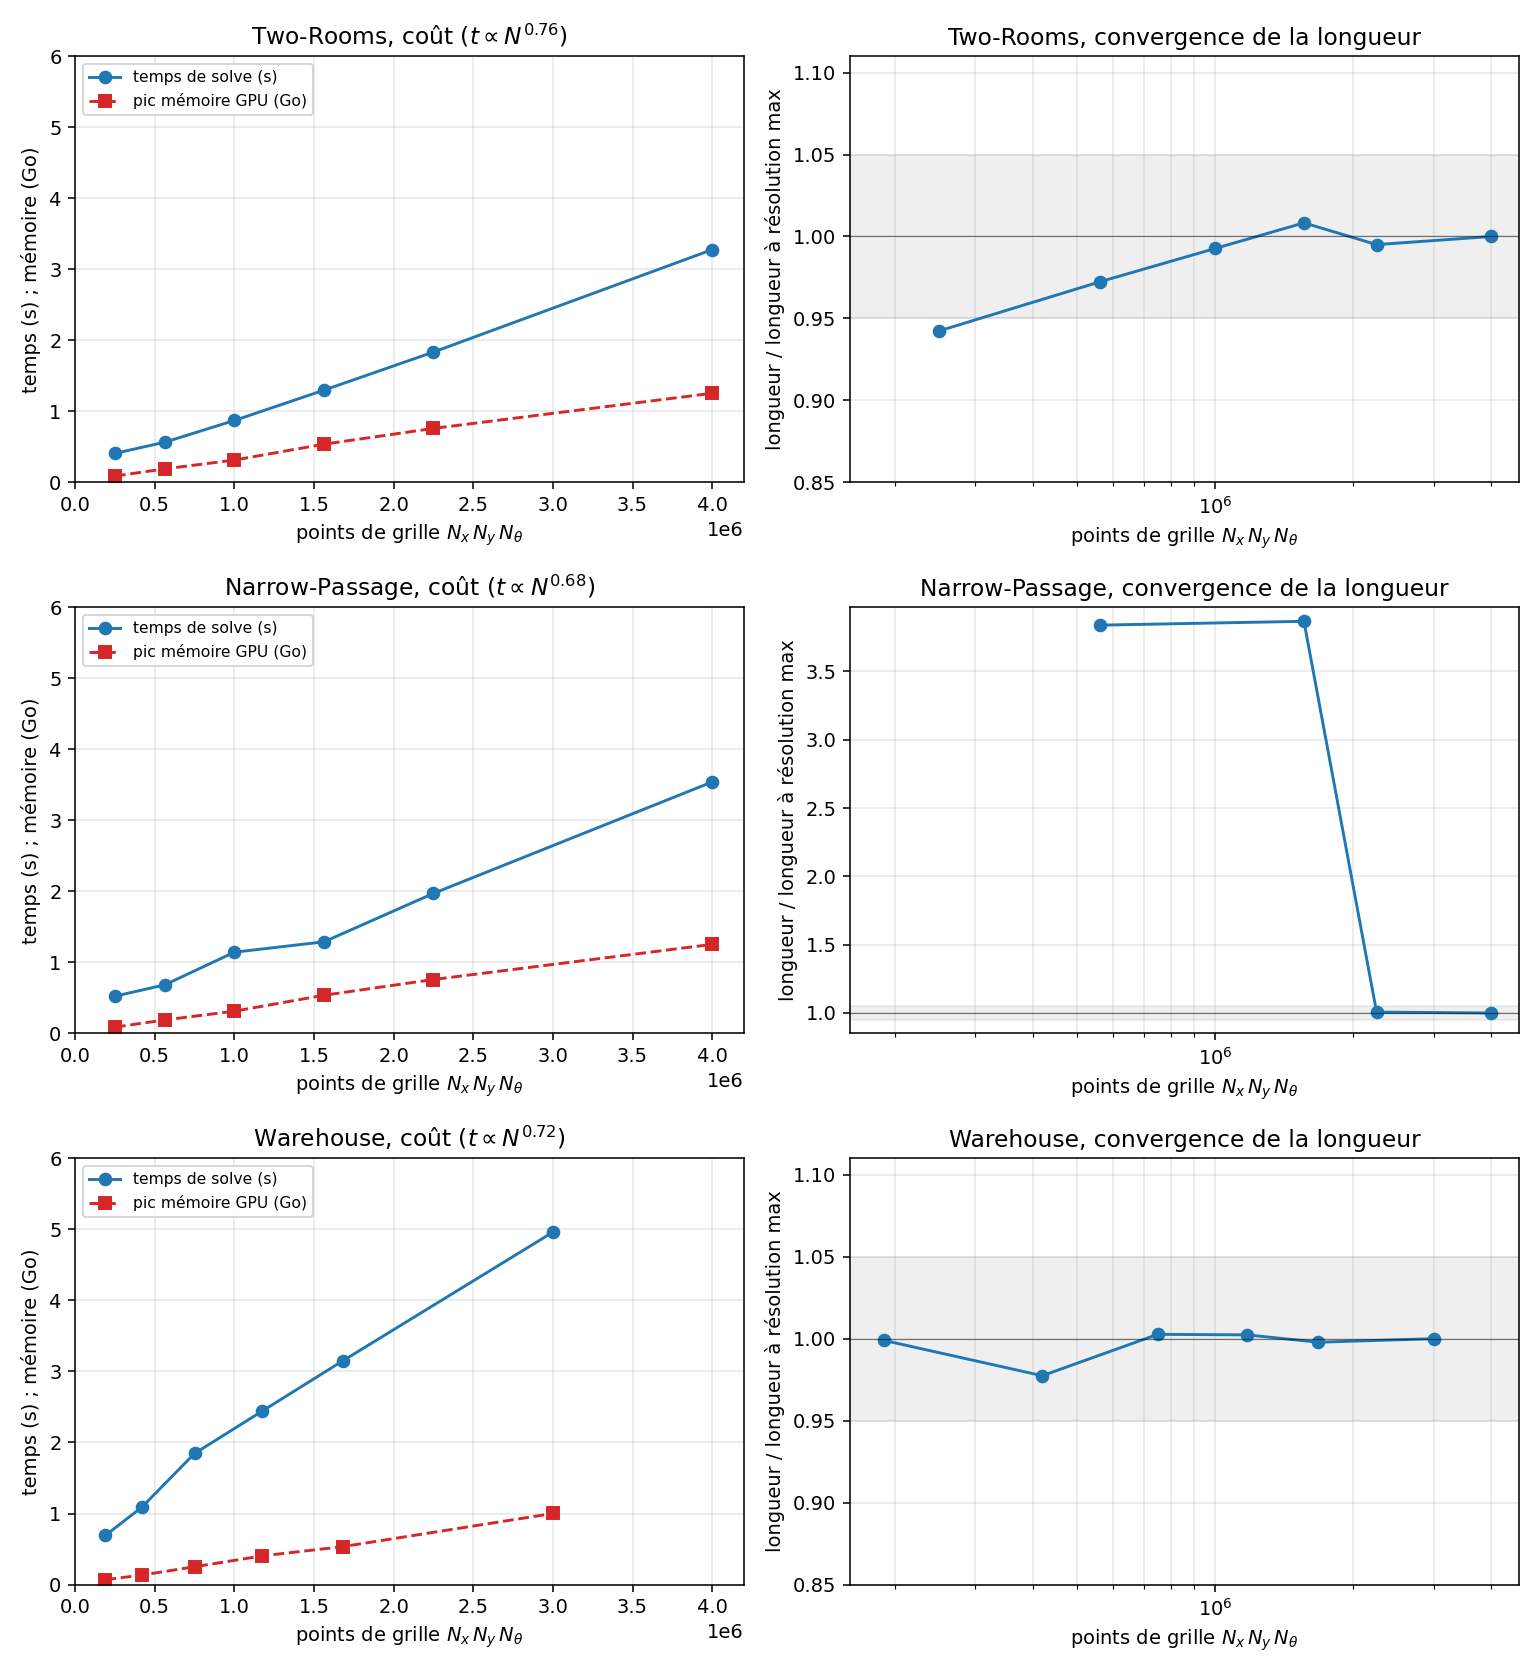

In [3]:
GEN.run("parameter_tables")      # writes figures/tables/parameter_study.md
show("resolution_cost_convergence.png")

On Two-Rooms the length stays within one percent of that of the finest grid
from 100 cells a side up, and falls six percent short on the coarsest grid. On
Warehouse every grid lies within 2.3 percent of the finest. On Narrow-Passage,
the extracted path does not join its two ends on the grids of 50 and 100 cells;
on those of 75 and 125 cells the passage is closed and the path goes round the
hall, nearly four times as long as on the finest grid; only from 150 cells does
it take the passage. A coarse grid cannot be trusted on the sole evidence that
it returned a path.

The times and the memory are those of the machine that measured them, an
NVIDIA T1200 with 4 GB, otherwise idle: on the finest Two-Rooms grid, four
million points, 3.28 s and 1254 MB. Notebook 8 measures the solve time on the
machine that runs it. The values of every grid are in
`figures/tables/parameter_study.md`, under *Grid resolution*.

<a id='2'></a>
## 2. How a coarse grid closes a passage

A schematic, not a solve. The passage of Narrow-Passage is 1.00 m wide and the
discs that cover the vehicle span 0.90 m. (a) With cells of 12.5 cm aligned on
the walls, the passage keeps its width and the discs go through. (b) With cells
of 20 cm, shifted against the walls, every cell that touches an obstacle is
marked: the passage falls to 0.80 m and the discs touch marked cells. (c) When a
corridor of the configuration space is only a cell or two wide, the extraction,
which interpolates the direction of descent from the free corners of the
current cell only, can enter a cell that has none and stop there: the paths
of section 1 that do not join their two ends, dashed in its first figure.

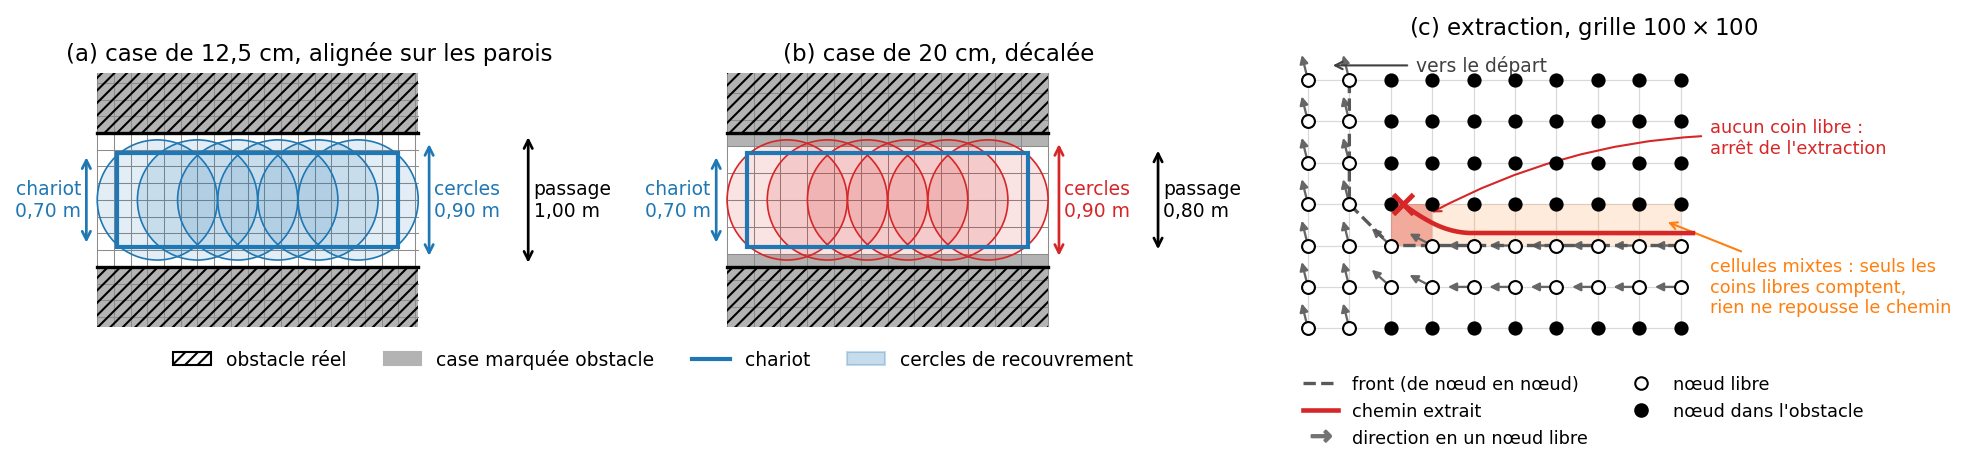

In [4]:
GEN.run("rasterisation")
show("np_rasterisation.png")

<a id='3'></a>
## 3. Five situations on Two-Rooms

We study the model parameters on Two-Rooms at 200 cells a side, 12.5 cm a
cell, with five pairs of poses. S1 crosses from one room to the other and S5
runs along the corridor; the other three impose a change of direction: R1 is a
U-turn in the corridor, R2 leaves a room whose back wall the vehicle faces, R3
ends in the other room facing its door.

The figure draws four of them, under the names the panels below carry:
Traversée (S1), Sortie (R2), Demi-tour (R1) and Entrée (R3), a disc at the
start and a square at the goal. The map is drawn in the orientation of the
comparisons, a quarter turn from the image as the sweeps read it.

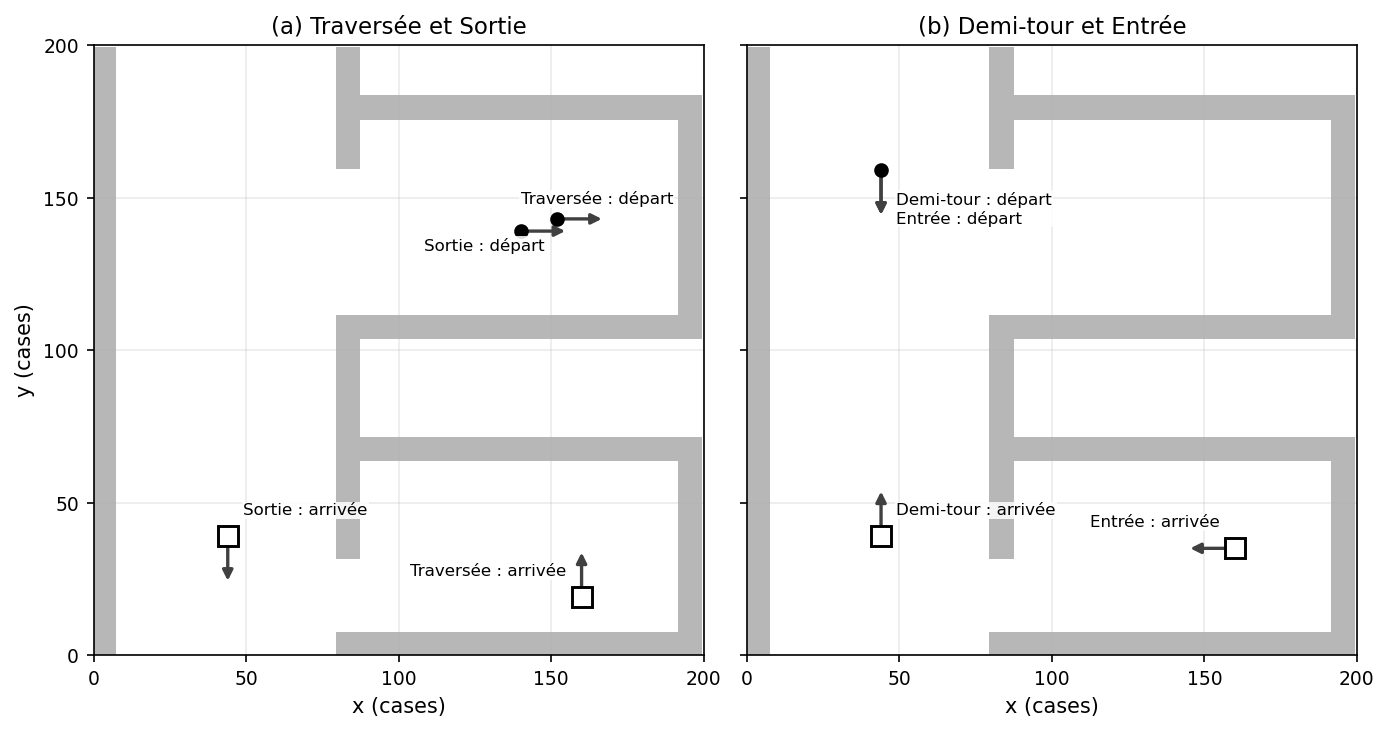

In [5]:
GEN.run("parameter_sweeps")
show("sens_situations.png")

<a id='4'></a>
## 4. One parameter at a time

Each sweep varies one parameter around the centre $k_1 = 10$, $k_2 = 50$,
$\nu_{FWD} = 3$, $\nu_{2WS} = 1.5$, $\nu_{4WS} = 0.5$, $\gamma_{rev} = 0.5$,
for the 4WS vehicle, the others held. The paths are coloured by the value of
the parameter, the reference marked with an asterisk, and the start of each
path is closed on the requested pose. Colouring by value rather than by a score
distinguishes two settings with equal scores but opposite behaviours.
The values of every sweep, situation by situation, are in
`figures/tables/parameter_study.md`, under *One-parameter sweeps*: swept area,
length, cusps, the share of the length driven backward (`backward`) and the
share of the points in a manoeuvring mode (`manoeuvre`); `nu_reverse` is
$\gamma_{rev}$.

**$k_1$**, the cost of reversing in navigation, on the U-turn and on the entry.

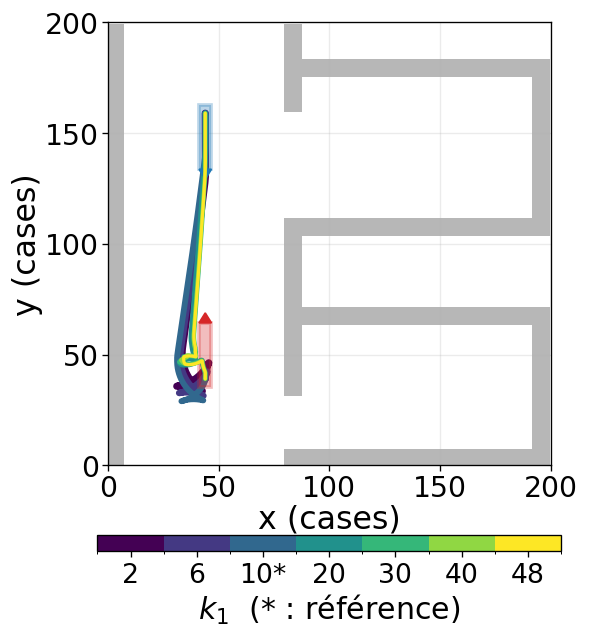

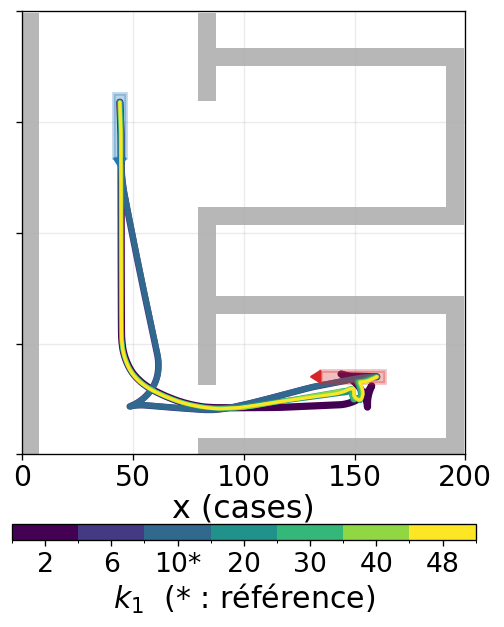

In [6]:
show("sens_k1_demitour.png")
show("sens_k1_entree.png")

Up to $k_1 = 10$ the U-turn R1 is made in navigation, with two to four cusps;
from $k_1 = 20$ the vehicle turns round in the manoeuvring mode, 30 to 48 % of
its points, and the path shortens from 160.6 cells to between 135 and 139. On
the entry R3 the reference reverses into the room, 44 % of the length driven
backward. From $k_1 = 20$ the vehicle enters forward and turns round in
manoeuvre (17 to 24 % of the points, 43 to 44 m² swept against 37.7); at
$k_1 = 2$ it turns round in navigation and sweeps 49.2 m².

**$\gamma_{rev}$**, the coefficient of backward navigation, on four situations.

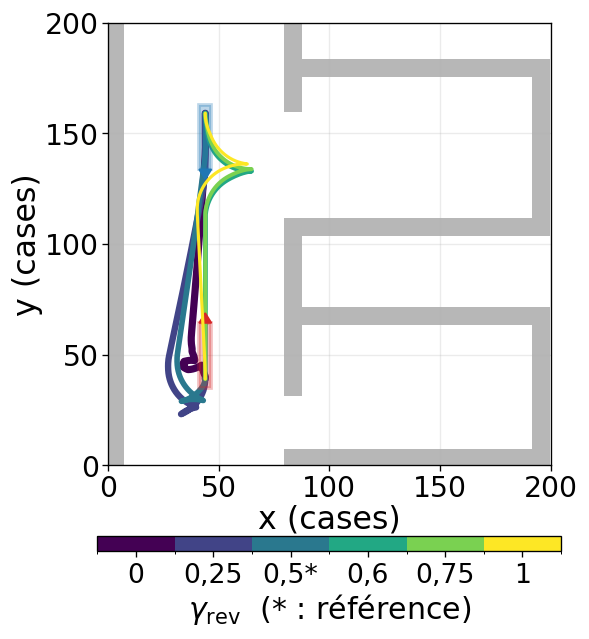

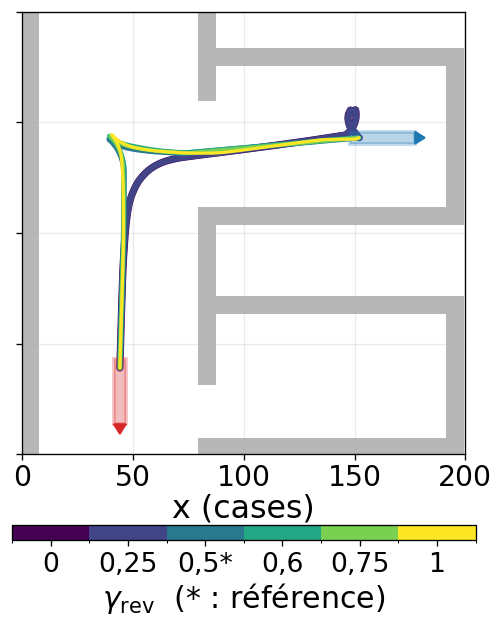

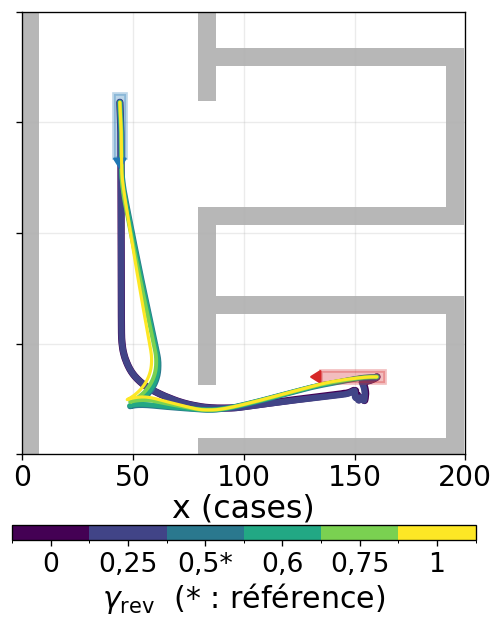

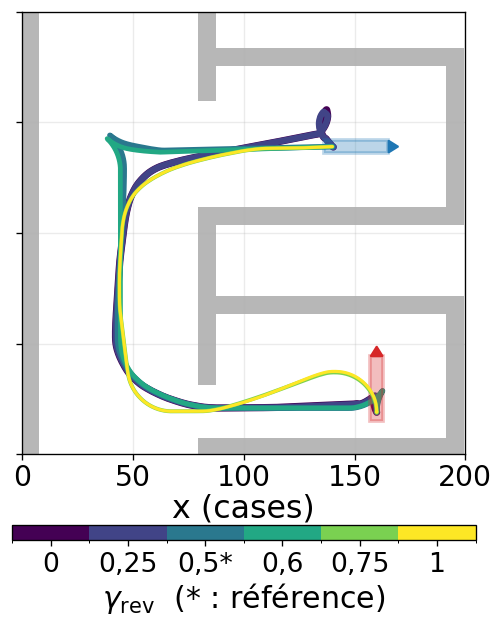

In [7]:
for name in ("sens_gamma_rev_demitour.png", "sens_gamma_rev_sortie.png",
             "sens_gamma_rev_entree.png", "sens_gamma_rev_traversee.png"):
    show(name)

$\gamma_{rev}$ acts through a threshold that depends on the situation: 0.35 on
R2, 0.45 on R3, 0.55 on R1. Below it on R2 and R3, reversing in navigation
costs too much and the vehicle turns round in the manoeuvring mode, on 27 % of
its points on R2, in a series of short back-and-forth moves (66 cusps), and on
14 to 19 % on R3; above it, it reverses in navigation, with one cusp on R2 and
one or two on R3. The reference, 0.5, lies above the thresholds of R2 and R3
and just below that of R1: from 0.55 the vehicle drives about three quarters of
the U-turn backward. R1 has a second threshold, at 0.25, below which it too
turns round in the manoeuvring mode. On S1 the whole crossing is driven
backward from 0.75, and below 0.3 the vehicle manoeuvres on 18 to 19 % of its
points.

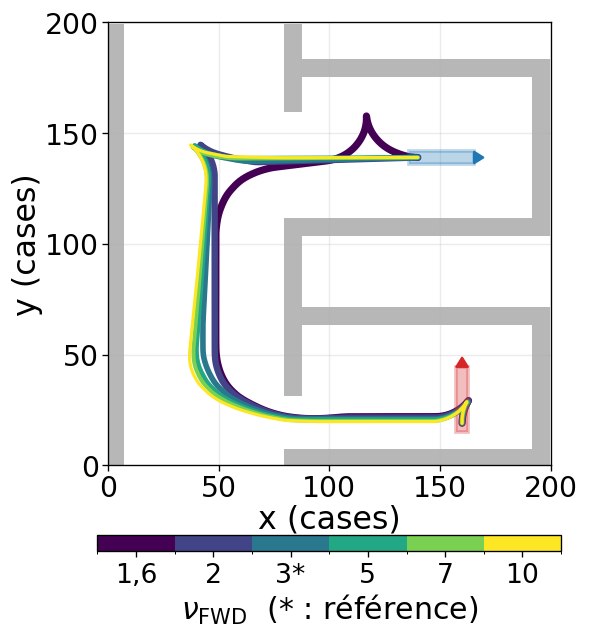

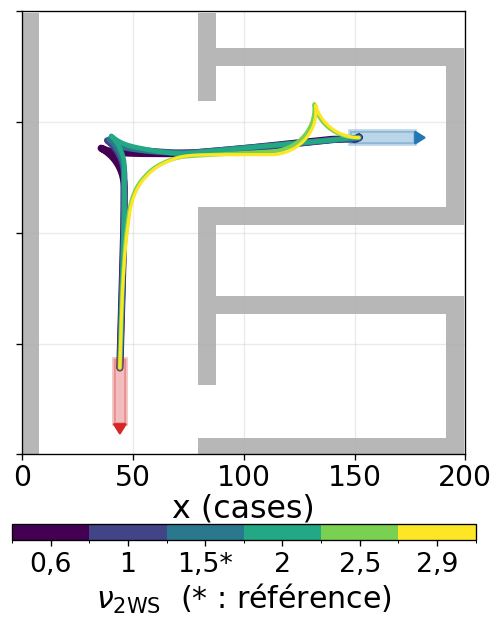

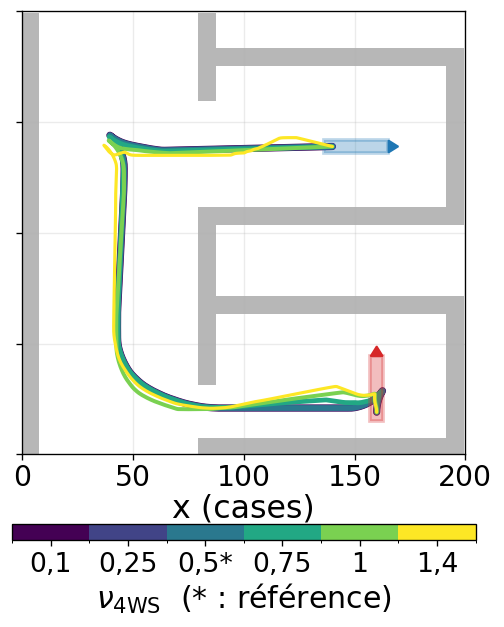

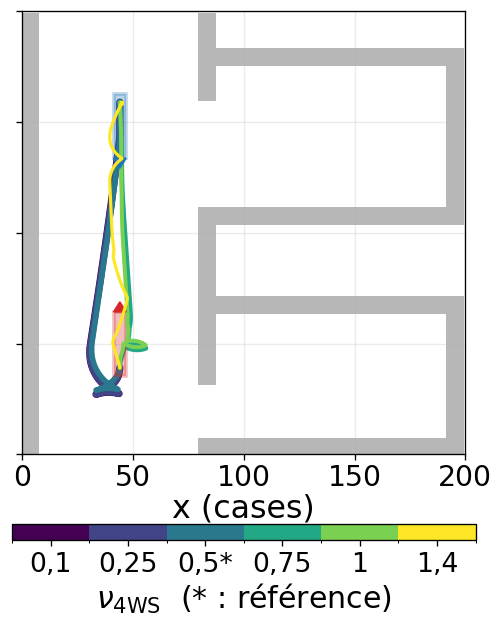

In [8]:
for name in ("sens_nu_FWD_traversee.png", "sens_nu_2WS_sortie.png",
             "sens_nu_4WS_traversee.png", "sens_nu_4WS_demitour.png"):
    show(name)

The speed coefficients act when one comes close to another. When $\nu_{FWD}$
comes down to $\nu_{2WS}$ (1.6 against 1.5, on S1), or $\nu_{2WS}$ rises
towards $\nu_{FWD}$ (2.5 and above, on R2), going straight is no longer
preferred to turning and the route changes: 68.6 m² swept on S1 against 57.8 at
the centre, 44.8 m² on R2 against 33.7. As $\nu_{4WS}$ rises, the vehicle
engages the manoeuvring mode: on R1 from 0.75, with 36 % of the points in
manoeuvre, and at 1.4, close to $\nu_{2WS}$, it manoeuvres almost everywhere
(99 %). Inside the ordering $\nu_{FWD} > \nu_{2WS} > \nu_{4WS}$ the planner
keeps navigation for open space; outside it, it still returns an optimal path,
for a cost that no longer describes the intended behaviour.

<a id='5'></a>
## 5. The transition costs, and the choice of (2, 3)

Two-Rooms seldom requires the manoeuvring mode, so the cost of entering it,
$k_2$, matters little there. The two campaign problems that do require it,
docking and Narrow-Passage (notebook 5), are solved over a grid of
$1 \le k_1 < k_2$, 4WS, reference speed coefficients. The panels draw the
$k_2$ sweep at $k_1 = 2$.

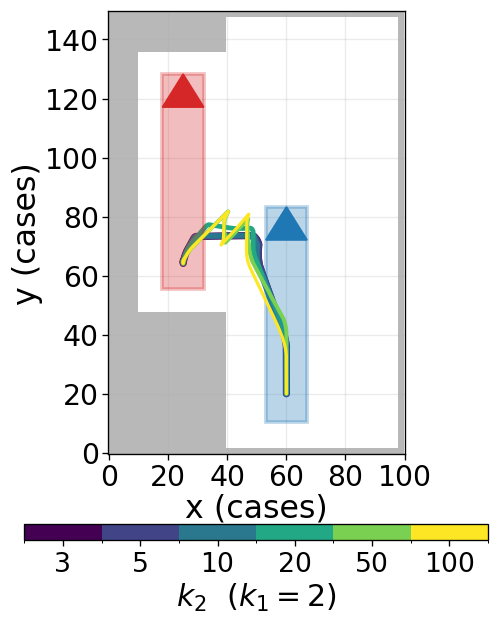

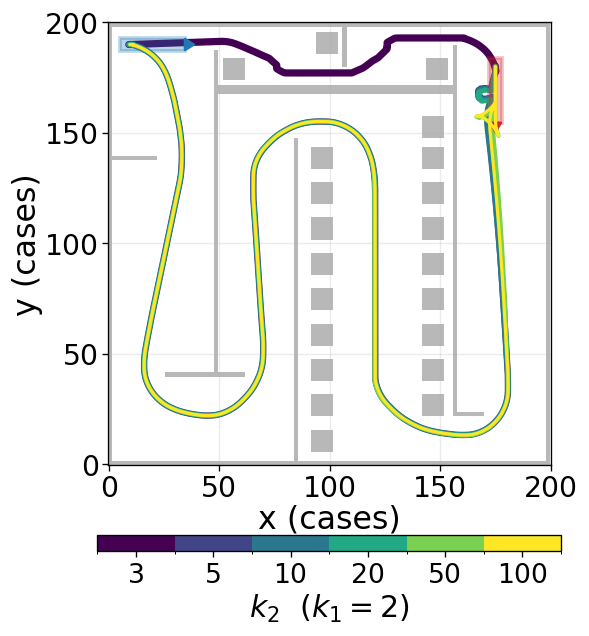

In [9]:
show("sens_k2_accostage.png")
show("sens_k2_np.png")

At $k_1 = 2$ the vehicle reaches the docking bay in crab for $k_2 \le 20$, 24
to 26 % of its points in manoeuvre, and in navigation for $k_2 = 50$ and 100.
It takes the narrow passage only for $k_2 = 3$, 191.3 cells, and goes round the
hall from $k_2 = 5$, 738 cells and more.

Over the whole grid (`figures/tables/parameter_study.md`, *Grid of transition
costs*), only three pairs take the passage, $(1, 2)$, $(1, 3)$ and $(2, 3)$, at
190.6 to 191.3 cells, against 735.8 or more for every other pair; at the
centre, $(10, 50)$, the vehicle goes round, 743.3 cells (752.5 for the shipped
path cited in notebook 5, section 6). The three also reach the docking bay in crab. On the
five situations their swept areas differ by at most 1.1 m², and $(2, 3)$ never
sweeps more than the other two. The comparisons with the sampling planners use
$(2, 3)$: of the three, it is the pair that keeps reversing in navigation
costlier than reversing within the manoeuvring mode, which costs 1.

Against the centre, solved as the sweeps are (same file, *(2, 3) against
(10, 50) on the situations*), $(2, 3)$ changes the swept area of the situations
by $-10.2$ % (R1) to $+22.6$ % (R3); on R3 the vehicle turns round with seven
cusps against two.

<a id='6'></a>
## 6. The cap on the obstacle cost

The local cost grows near obstacles, through the clearance term of the speed
field, and that term is capped. We compare eight caps, from no obstacle cost
(`sans coût`) to no cap (`sans plafond`), on Two-Rooms, Warehouse and the
twenty procedural maps, for both vehicles, at $(2, 3)$; the cap of the other
studies here is the vehicle length $L$, except the resolution study of section
1, which solves Two-Rooms and Warehouse without it. The labels `L/4` to `2L`
are multiples of that length, which the thesis writes $L_{tot}$, keeping $L$
for the wheelbase as notebook 1 does. The cap only acts where the clearance
would exceed it, so it shapes the path in open space and not in narrow
passages.

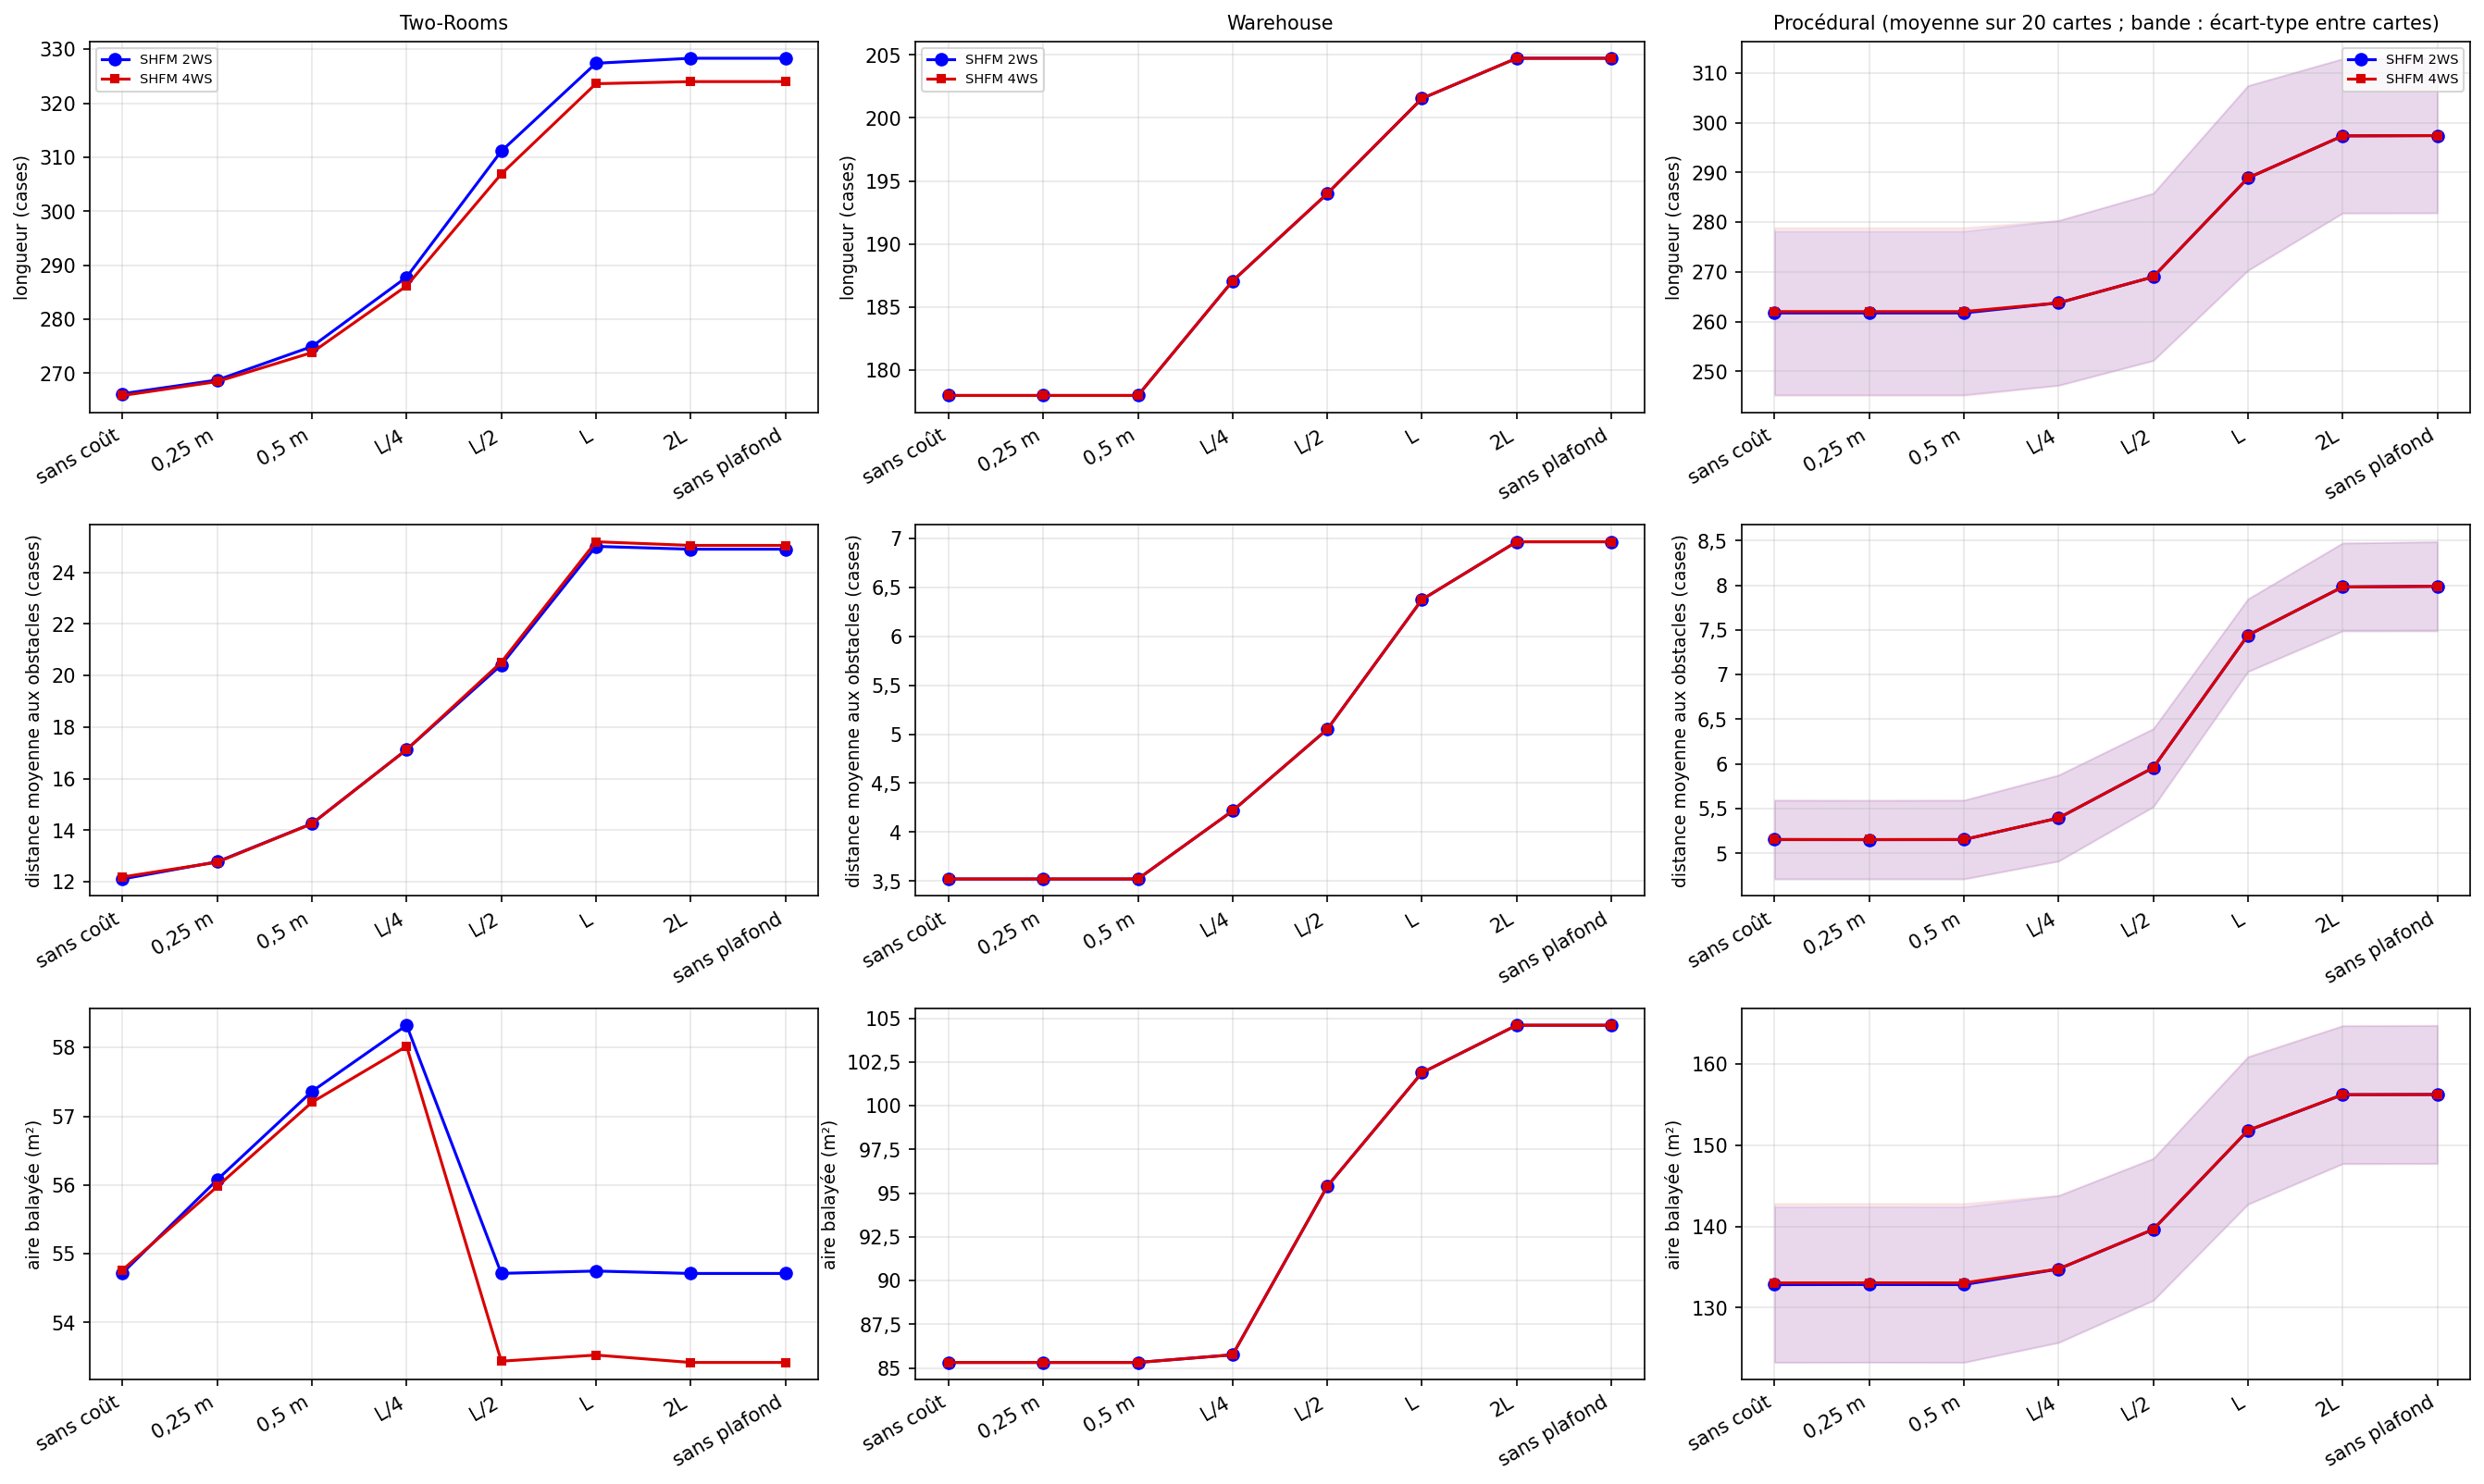

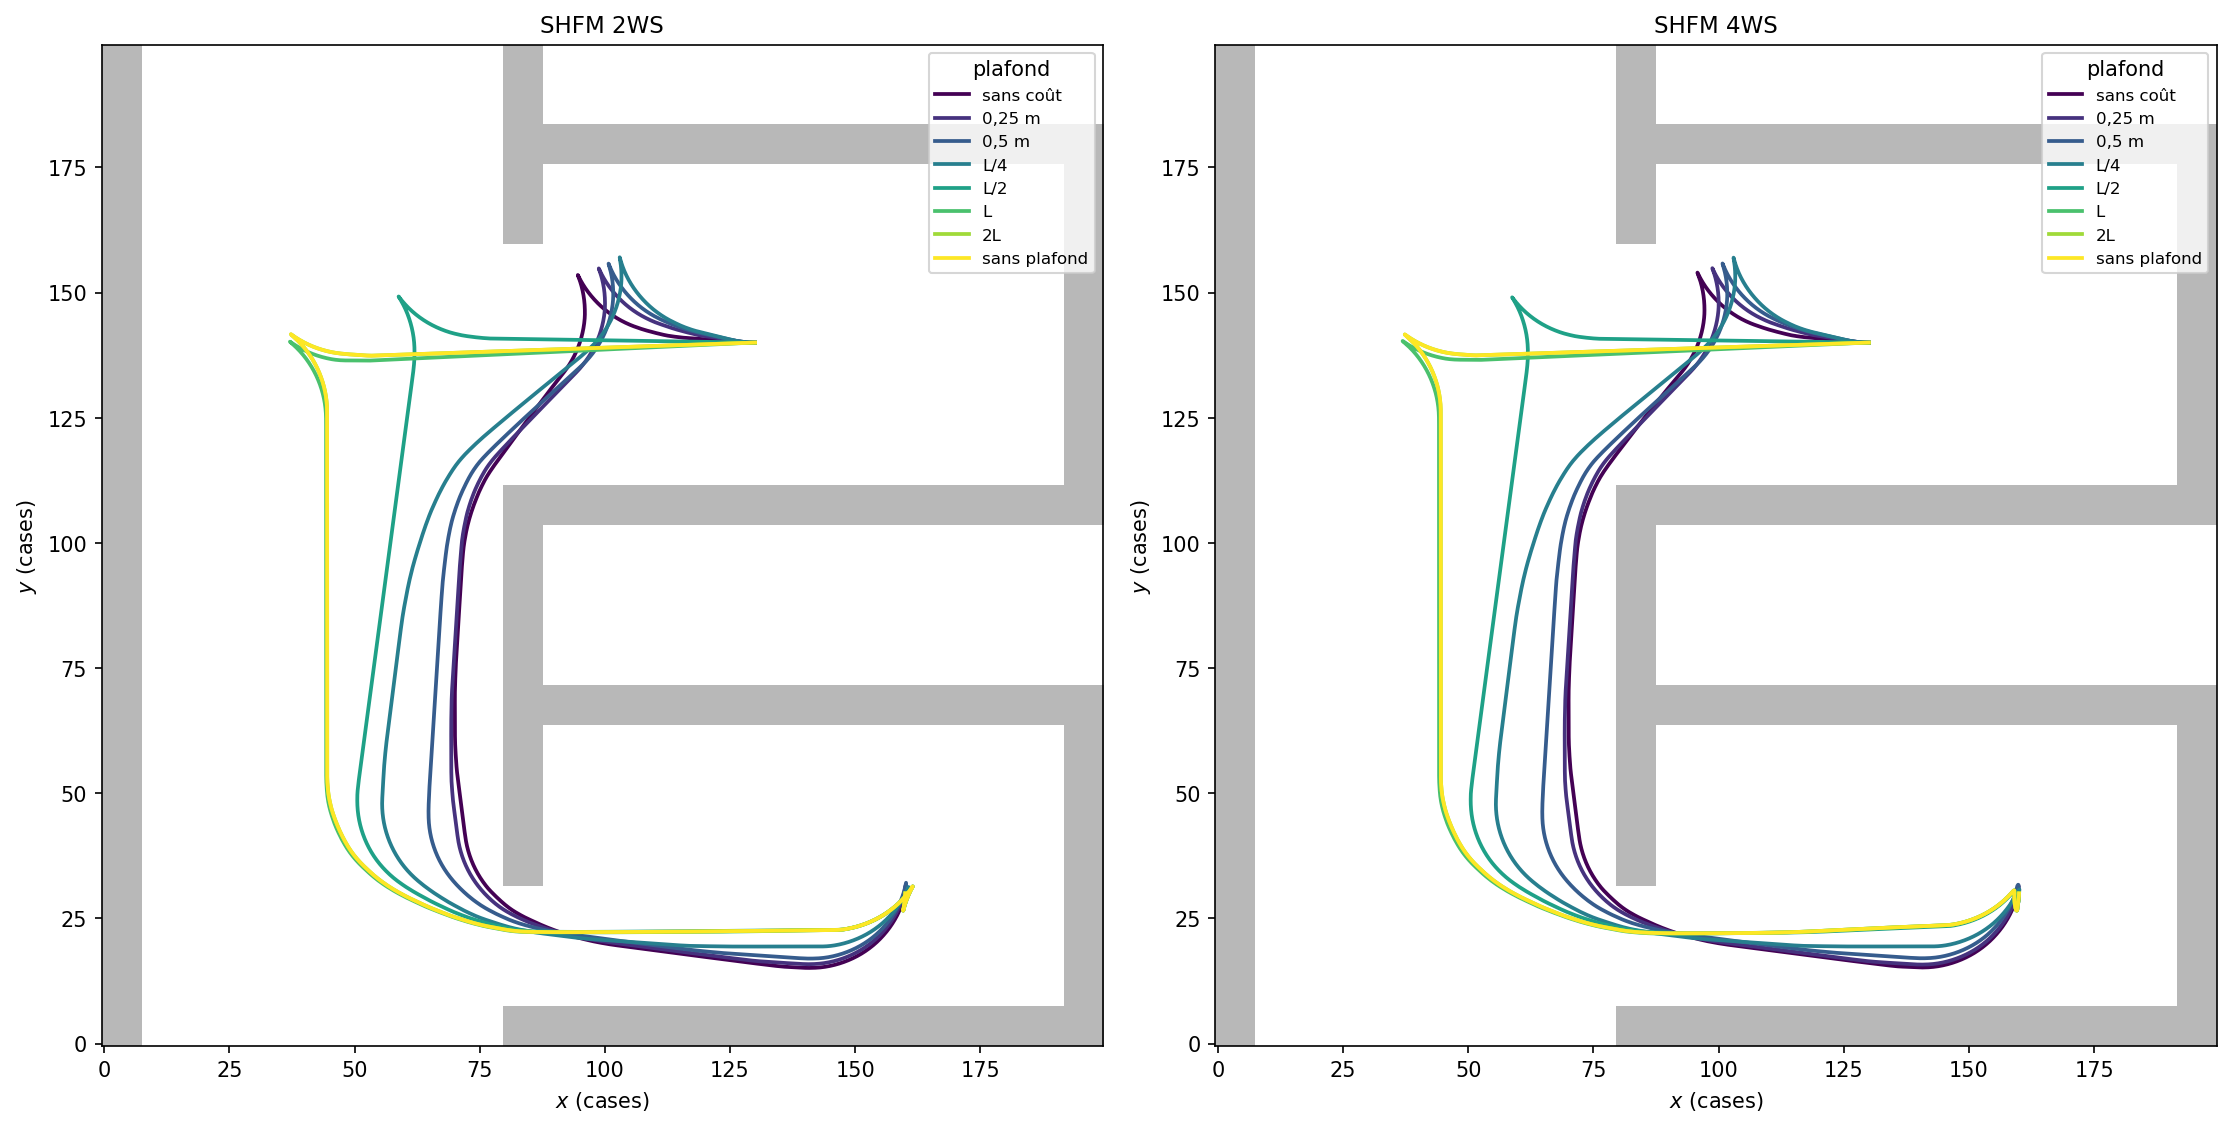

In [10]:
GEN.run("clearance_cap")
show("saturation_metriques.png")
show("saturation_traj_two_rooms.png")

Without obstacle cost the path is a pure geodesic and runs along the walls: on
Two-Rooms, in 2WS, 2.44 cells from the obstacles at the closest and 12.11 on
average. Raising the cap moves the path away from the walls and lengthens it,
as the first figure above shows: with the cap at $L$, 8.20 cells at the closest and
25.01 on average, for 327.4 cells against 266.2. From $2L$ on the cap no longer
acts. Warehouse and the procedural maps follow the same order. On every scene
RRT* and Informed-RRT* run closer to the walls than our paths at $L$: on
Two-Rooms 2.71 and 2.68 cells at the closest, for paths of 248.8 and 247.7
cells. The values of every cap and both vehicles are in
`figures/tables/clearance_cap.md`.

---

Previous: [5. Precision docking and narrow passages](05_precision_docking.ipynb)
Next: [7. Benchmarks](07_benchmarks.ipynb)